# Credit Default Risk, Part 2: Stress-testing the decision rule

Notebook 01 found a model that cuts expected loan losses by about **66%** on the test set.
This notebook asks the questions a credit-risk team would ask before trusting that number:

1. **Cost sensitivity:** does the conclusion survive if the $10,000 / $500 cost guesses are wrong?
2. **Review capacity:** what if analysts can only review a fixed share of applications?
3. **Fairness audit:** who gets approved, and does the rule pass the 4/5ths test?
4. **Drift monitoring:** how would we notice the applicant population changing?
5. **Hyperparameter tuning:** is the champion leaving performance on the table?

Reusable code lives in `src/credit_risk/`; this notebook only orchestrates and plots.
Run `python -m credit_risk.train` first to create `artifacts/model.joblib`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve() / "src"))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from credit_risk.config import COST_FN, COST_FP, MODEL_PATH, NUM_COLS, CAT_COLS, RANDOM_STATE, SENSITIVE
from credit_risk.costs import optimal_threshold, total_cost, cost_curve, THRESHOLDS
from credit_risk.data import load_data, split, age_band
from credit_risk.fairness import audit
from credit_risk.models import candidate_models, fit_params
from credit_risk.monitoring import psi_report

sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
TEAL, RUST, GREY = "#3b7d8c", "#a64b23", "#7a7a7a"

art = joblib.load(MODEL_PATH)
pipe, CHAMPION, THR = art["pipeline"], art["model_name"], art["threshold"]
X_train, X_test, y_train, y_test = split(load_data())
print(f"Champion: {CHAMPION} @ threshold {THR}")

# Out-of-fold scores on the training set: all threshold choices below use these, never the test set.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
needs_w = "HistGB" in CHAMPION
oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1,
                        params=fit_params(y_train, needs_w))[:, 1]
p_test = pipe.predict_proba(X_test)[:, 1]
BASELINE = total_cost(y_test, np.zeros(len(y_test)))
print(f"Approve-everyone test cost: ${BASELINE:,.0f}")

Champion: HistGB (balanced) @ threshold 0.27
Approve-everyone test cost: $59,310,000


## 1. Cost sensitivity

A missed default costs `C_FN`; reviewing a good borrower costs `C_FP`. Only the **ratio** matters
for the decision. Reviewing is worth it when the chance of default exceeds the break-even value
**p\* = C_FP / (C_FN + C_FP)**. At 20:1 that is only **4.8%**, far below the 11.6% average
default rate. That is why the model reviews so many applicants.

We keep `C_FP = $500` and vary the ratio from 2:1 to 50:1, re-tuning the threshold each time.

In [2]:
rows = []
for ratio in [2, 3, 5, 8, 10, 15, 20, 30, 40, 50]:
    c_fn = ratio * COST_FP
    thr, _ = optimal_threshold(y_train, oof, c_fn=c_fn, c_fp=COST_FP)
    flag = (p_test >= thr).astype(int)
    base = total_cost(y_test, np.zeros(len(y_test)), c_fn=c_fn, c_fp=COST_FP)
    model = total_cost(y_test, flag, c_fn=c_fn, c_fp=COST_FP)
    rows.append({"cost ratio": f"{ratio}:1", "ratio": ratio, "threshold": thr,
                 "break-even p*": round(COST_FP / (c_fn + COST_FP), 3),
                 "review rate": flag.mean(), "savings %": (base - model) / base,
                 "savings $M": (base - model) / 1e6,
                 "defaults caught": flag[y_test.values == 1].mean()})
sweep = pd.DataFrame(rows).set_index("cost ratio")
display_cols = ["threshold", "break-even p*", "review rate", "defaults caught", "savings %", "savings $M"]
sweep[display_cols].style.format({"threshold": "{:.2f}", "break-even p*": "{:.3f}", "review rate": "{:.1%}",
                                   "defaults caught": "{:.1%}", "savings %": "{:.1%}", "savings $M": "{:.2f}"})

,threshold,break-even p*,review rate,defaults caught,savings %,savings $M
cost ratio,,,,,,
2:1,0.78,0.333,4.9%,19.4%,8.2%,0.49
3:1,0.71,0.250,10.2%,32.5%,14.1%,1.25
5:1,0.60,0.167,21.8%,53.1%,26.2%,3.88
8:1,0.48,0.111,37.5%,71.2%,39.7%,9.41
10:1,0.43,0.091,45.1%,77.5%,46.4%,13.76
15:1,0.32,0.062,63.3%,88.9%,58.5%,26.02
20:1,0.27,0.048,72.2%,92.8%,66.4%,39.35
30:1,0.19,0.032,86.0%,97.3%,75.9%,67.50
40:1,0.14,0.024,93.5%,99.0%,81.3%,96.47


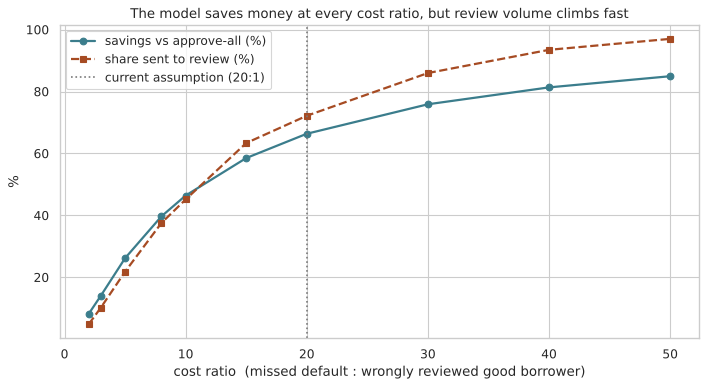

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sweep["ratio"], sweep["savings %"] * 100, "o-", color=TEAL, lw=2, label="savings vs approve-all (%)")
ax.plot(sweep["ratio"], sweep["review rate"] * 100, "s--", color=RUST, lw=2, label="share sent to review (%)")
ax.axvline(COST_FN / COST_FP, color=GREY, ls=":", label="current assumption (20:1)")
ax.set_xlabel("cost ratio  (missed default : wrongly reviewed good borrower)")
ax.set_ylabel("%")
ax.set_title("The model saves money at every cost ratio, but review volume climbs fast")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "cost_sensitivity.png", dpi=130); plt.show()

**Reading it.** Savings stay positive across the whole range, so "the model beats approve-everyone"
holds even if the cost estimates are off by a factor of 4 either way. What is *not* robust is the
operating point: from 10:1 to 20:1 the share of applications sent to review rises steeply. The cost
ratio is a business decision that needs real loss data, not a modelling detail.

## 2. Review capacity

At 20:1 the cost-optimal rule sends about 72% of applications to review, which few lending teams
could staff. A more realistic rule is: *"we can review K% of applications, so review the riskiest K%."*
The cut-off is the (1 - K) quantile of the training OOF scores.

In [4]:
cap_rows = []
for k in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.72]:
    thr_k = float(np.quantile(oof, 1 - k))
    flag = (p_test >= thr_k).astype(int)
    cost = total_cost(y_test, flag)
    cap_rows.append({"review capacity": k, "threshold": thr_k, "actual review rate": flag.mean(),
                     "defaults caught": flag[y_test.values == 1].mean(),
                     "savings $M": (BASELINE - cost) / 1e6, "savings %": (BASELINE - cost) / BASELINE})
cap = pd.DataFrame(cap_rows)
max_sav = total_cost(y_test, np.zeros(len(y_test))) - total_cost(y_test, (p_test >= THR).astype(int))
cap["share of max savings"] = cap["savings $M"] * 1e6 / max_sav
cap.style.format({"review capacity": "{:.0%}", "threshold": "{:.3f}", "actual review rate": "{:.1%}",
                  "defaults caught": "{:.1%}", "savings $M": "{:.2f}", "savings %": "{:.1%}",
                  "share of max savings": "{:.0%}"}).hide(axis="index")

review capacity,threshold,actual review rate,defaults caught,savings $M,savings %,share of max savings
5%,0.771,5.4%,21.1%,11.77,19.8%,30%
10%,0.708,10.3%,32.8%,17.82,30.0%,45%
20%,0.611,20.5%,51.3%,26.73,45.1%,68%
30%,0.532,30.2%,63.3%,31.69,53.4%,81%
40%,0.463,40.1%,73.3%,35.39,59.7%,90%
50%,0.400,49.8%,81.0%,37.76,63.7%,96%
60%,0.340,59.8%,87.0%,38.93,65.6%,99%
72%,0.271,71.9%,92.7%,39.39,66.4%,100%


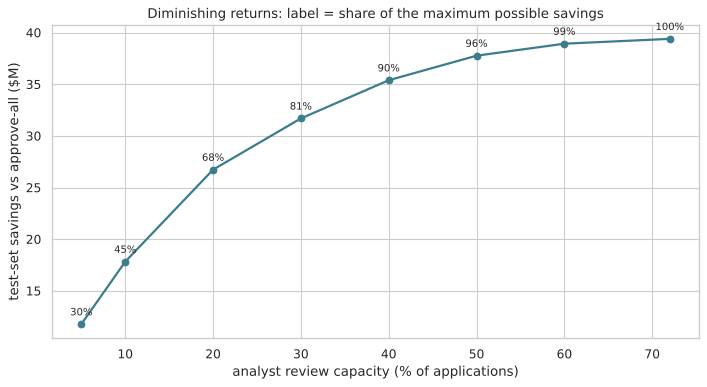

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cap["review capacity"] * 100, cap["savings $M"], "o-", color=TEAL, lw=2)
for _, r in cap.iterrows():
    ax.annotate(f"{r['share of max savings']:.0%}", (r["review capacity"] * 100, r["savings $M"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xlabel("analyst review capacity (% of applications)")
ax.set_ylabel("test-set savings vs approve-all ($M)")
ax.set_title("Diminishing returns: label = share of the maximum possible savings")
plt.tight_layout(); plt.savefig(FIG / "review_capacity.png", dpi=130); plt.show()

**Reading it.** Savings follow a curve of diminishing returns. The riskiest applicants are reviewed
first, so reviewing just **20% of applications captures 68% of the maximum savings, and 30% captures
81%**. The last 40 points of review volume add less than a fifth of the value. This is
the chart to bring to the operations team: it turns "how many analysts do we hire?" into a
dollar question.

## 3. Fairness audit

`Age`, `MaritalStatus` and `HasDependents` are protected characteristics, or close proxies for them,
in many jurisdictions. For each group we report the approval rate and the **disparate-impact (DI)
ratio**: the group's approval rate divided by the best-treated group's. The common "4/5ths rule"
flags DI < 0.80.

In [6]:
def fairness_table(flag, frame=X_test):
    f = frame.assign(AgeBand=age_band(frame["Age"]))
    out = []
    for col, rep in audit(f, y_test, flag, SENSITIVE).items():
        rep = rep.reset_index(); rep.insert(0, "attribute", col); out.append(rep)
    return pd.concat(out, ignore_index=True)

flag_default = (p_test >= THR).astype(int)
fair = fairness_table(flag_default)
fair.style.format({"actual_default_rate": "{:.1%}", "approval_rate": "{:.1%}", "false_negative_rate": "{:.1%}",
                   "false_positive_rate": "{:.1%}", "disparate_impact": "{:.2f}"}).hide(axis="index")

attribute,group,n,actual_default_rate,approval_rate,false_negative_rate,false_positive_rate,disparate_impact,passes_4_5ths
AgeBand,18-25,7801,20.7%,3.5%,0.7%,95.7%,0.06,False
AgeBand,26-35,9896,16.5%,8.6%,2.0%,90.1%,0.15,False
AgeBand,36-45,9981,11.6%,19.3%,5.8%,78.9%,0.33,False
AgeBand,46-55,9779,8.2%,33.2%,12.7%,64.9%,0.57,False
AgeBand,56-69,13613,5.3%,58.1%,30.2%,40.4%,1.00,True
MaritalStatus,Divorced,17001,12.7%,26.3%,6.7%,70.9%,0.87,True
MaritalStatus,Married,17041,10.0%,30.2%,7.4%,67.3%,1.00,True
MaritalStatus,Single,17028,12.1%,27.0%,7.6%,70.3%,0.90,True
HasDependents,No,25604,12.6%,23.9%,6.1%,73.6%,0.75,False
HasDependents,Yes,25466,10.6%,31.8%,8.5%,65.4%,1.00,True


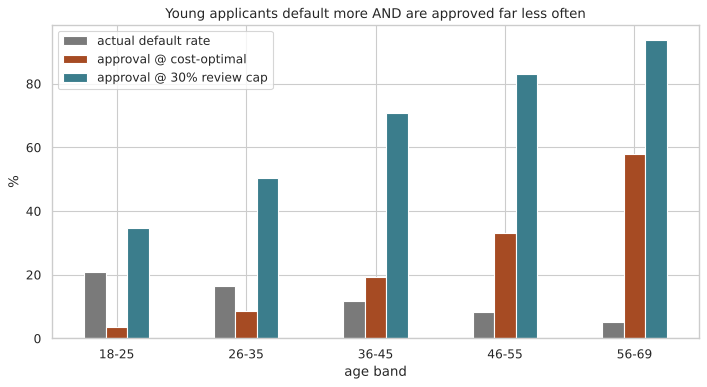

,actual default rate,approval @ cost-optimal,approval @ 30% review cap
group,,,
18-25,20.7%,3.5%,34.6%
26-35,16.5%,8.6%,50.3%
36-45,11.6%,19.3%,70.9%
46-55,8.2%,33.2%,83.1%
56-69,5.3%,58.1%,93.9%


In [7]:
thr30 = float(np.quantile(oof, 0.70))
flag30 = (p_test >= thr30).astype(int)
age_tbl = pd.DataFrame({
    "actual default rate": fairness_table(flag_default).query("attribute == 'AgeBand'").set_index("group")["actual_default_rate"],
    "approval @ cost-optimal": fairness_table(flag_default).query("attribute == 'AgeBand'").set_index("group")["approval_rate"],
    "approval @ 30% review cap": fairness_table(flag30).query("attribute == 'AgeBand'").set_index("group")["approval_rate"],
})
ax = (age_tbl * 100).plot.bar(figsize=(9, 5), color=[GREY, RUST, TEAL], rot=0)
ax.set_ylabel("%"); ax.set_xlabel("age band")
ax.set_title("Young applicants default more AND are approved far less often")
plt.tight_layout(); plt.savefig(FIG / "fairness_age.png", dpi=130); plt.show()
age_tbl.style.format("{:.1%}")

**Finding.** The rule **fails the 4/5ths test by age**: applicants aged 18-25 are approved a small
fraction as often as those aged 56-69. The model is not miscalibrated. In this dataset young
applicants really do default about 4x as often. Being accurate does not make a rule acceptable:
using age this way would need legal review in most lending regimes.

### Mitigation experiment: remove `Age` from the model

"Fairness through unawareness" is the simplest fix. Because this dataset's features are
generated independently, nothing else can stand in for age, so the gap should close. The question
is what it costs.

In [8]:
from sklearn.base import clone
from credit_risk.models import build_preprocessor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_wo_age = [c for c in NUM_COLS if c != "Age"]
pipe_wo_age = clone(pipe)
pipe_wo_age.set_params(prep=ColumnTransformer([
    ("num", StandardScaler(), num_wo_age),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), CAT_COLS),
]))
oof_wo = cross_val_predict(pipe_wo_age, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1,
                           params=fit_params(y_train, needs_w))[:, 1]
thr_wo, _ = optimal_threshold(y_train, oof_wo)
pipe_wo_age.fit(X_train, y_train, **fit_params(y_train, needs_w))
p_wo = pipe_wo_age.predict_proba(X_test)[:, 1]
flag_wo = (p_wo >= thr_wo).astype(int)

from sklearn.metrics import roc_auc_score
def age_di(flag):
    t = fairness_table(flag).query("attribute == 'AgeBand'")
    return t["disparate_impact"].min()

compare = pd.DataFrame({
    "with Age": {"ROC AUC": roc_auc_score(y_test, p_test), "threshold": THR,
                 "test cost $M": total_cost(y_test, flag_default) / 1e6,
                 "review rate": flag_default.mean(), "worst age-band DI": age_di(flag_default)},
    "without Age": {"ROC AUC": roc_auc_score(y_test, p_wo), "threshold": thr_wo,
                    "test cost $M": total_cost(y_test, flag_wo) / 1e6,
                    "review rate": flag_wo.mean(), "worst age-band DI": age_di(flag_wo)},
}).T
compare["extra cost $M"] = compare["test cost $M"] - compare.loc["with Age", "test cost $M"]
compare.style.format({"ROC AUC": "{:.4f}", "threshold": "{:.2f}", "test cost $M": "{:.2f}",
                      "review rate": "{:.1%}", "worst age-band DI": "{:.2f}", "extra cost $M": "{:+.2f}"})

,ROC AUC,threshold,test cost $M,review rate,worst age-band DI,extra cost $M
with Age,0.7576,0.27,19.96,72.2%,0.06,+0.00
without Age,0.7098,0.28,21.36,81.1%,0.91,+1.40


**Trade-off.** Removing `Age` drops ROC AUC from 0.758 to 0.710 and raises test-set losses by
about **$1.4M (+7%)**. In exchange, the worst age-band disparate-impact ratio rises from **0.06 to 0.91**,
which **passes** the 4/5ths rule. This is the price of the fairness constraint, and the table puts a
dollar figure on it. Deciding whether to pay it belongs to risk, legal and compliance, not to the
data scientist alone. The job of the model is to make the trade-off visible.

## 4. Drift monitoring with the Population Stability Index (PSI)

PSI compares a feature's distribution today against the training reference.
Rule of thumb: < 0.10 stable, 0.10-0.25 moderate shift, > 0.25 major shift.

First a sanity check (test set vs training sample should be stable), then a simulated
**economic downturn**: incomes fall 15%, rates rise 3 points, and more young applicants arrive.

In [9]:
reference = art["reference_sample"]
stable = psi_report(reference, X_test, NUM_COLS, CAT_COLS)
print("Test set vs training reference - max PSI:", round(stable["psi"].max(), 4))

rng = np.random.default_rng(RANDOM_STATE)
w = np.where(X_test["Age"] < 30, 3.0, 1.0)
downturn = X_test.sample(len(X_test), replace=True, weights=w, random_state=RANDOM_STATE).reset_index(drop=True)
downturn["Income"] = (downturn["Income"] * 0.85).clip(lower=15000)
downturn["InterestRate"] = (downturn["InterestRate"] + 3).clip(upper=25)
downturn.loc[rng.random(len(downturn)) < 0.10, "EmploymentType"] = "Unemployed"

drift = psi_report(reference, downturn, NUM_COLS, CAT_COLS)
drift.style.format({"psi": "{:.3f}"}).hide(axis="index")

Test set vs training reference - max PSI: 0.0031


feature,psi,status
InterestRate,1.255,major shift
Income,1.247,major shift
Age,0.253,major shift
EmploymentType,0.027,stable
MonthsEmployed,0.004,stable
LoanPurpose,0.002,stable
DTIRatio,0.001,stable
LoanAmount,0.001,stable
CreditScore,0.001,stable
Education,0.001,stable


Share sent to review: 72.2% (today) -> 86.3% (downturn)
Mean risk score:      0.420 -> 0.527


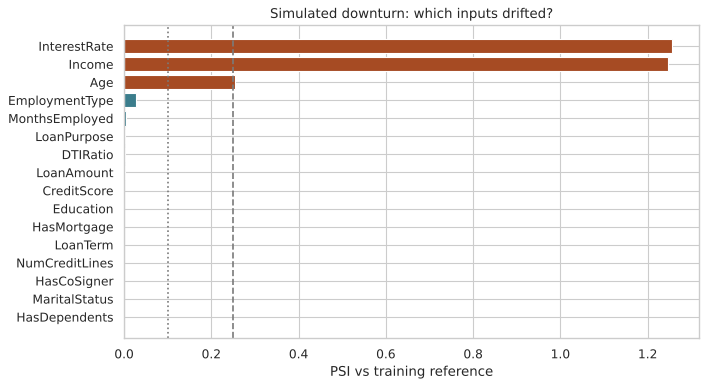

In [10]:
colors = drift["status"].map({"stable": TEAL, "moderate shift": "#d9a400", "major shift": RUST})
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(drift["feature"][::-1], drift["psi"][::-1], color=colors[::-1])
ax.axvline(0.10, color=GREY, ls=":"); ax.axvline(0.25, color=GREY, ls="--")
ax.set_xlabel("PSI vs training reference"); ax.set_title("Simulated downturn: which inputs drifted?")
plt.tight_layout(); plt.savefig(FIG / "drift_psi.png", dpi=130); plt.show()

p_down = pipe.predict_proba(downturn)[:, 1]
print(f"Share sent to review: {flag_default.mean():.1%} (today) -> {(p_down >= THR).mean():.1%} (downturn)")
print(f"Mean risk score:      {p_test.mean():.3f} -> {p_down.mean():.3f}")

**Reading it.** PSI catches the downturn in the inputs right away, **before** any loans have had
time to default and confirm it in the labels. In production this report would run weekly, and a
feature crossing 0.25 would trigger a review and possibly retraining. The jump in review volume is
the operational warning that comes with it.

## 5. Hyperparameter tuning

Randomised search over HistGradientBoosting settings with 3-fold CV on the training set
(ROC AUC), using the same balanced sample weights. The test set is used once at the end.

In [11]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

hgb, _ = candidate_models(include_rf=False)["HistGB (balanced)"]
search = RandomizedSearchCV(
    hgb,
    {"model__learning_rate": loguniform(0.02, 0.2),
     "model__max_leaf_nodes": randint(8, 64),
     "model__min_samples_leaf": randint(20, 300),
     "model__l2_regularization": loguniform(1e-3, 10)},
    n_iter=12, cv=3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1, refit=True)
search.fit(X_train, y_train, **fit_params(y_train, True))

tuned_auc = roc_auc_score(y_test, search.predict_proba(X_test)[:, 1])
print("Best CV AUC:", round(search.best_score_, 4))
print("Best params:", {k.split("__")[1]: (round(float(v), 4) if isinstance(v, float) else int(v))
                       for k, v in search.best_params_.items()})
print(f"Test AUC: default HistGB {roc_auc_score(y_test, p_test):.4f} -> tuned {tuned_auc:.4f}")

Best CV AUC: 0.7523
Best params: {'l2_regularization': 0.0084, 'learning_rate': 0.0348, 'max_leaf_nodes': 14, 'min_samples_leaf': 283}
Test AUC: default HistGB 0.7576 -> tuned 0.7585


**Reading it.** Tuning moves test AUC by less than 0.001 (0.7576 to 0.7585). This supports the warning in
notebook 01: the dataset has a low signal ceiling (about 0.76), so the gains that matter come
from the **decision rule** (threshold, capacity, fairness), not from squeezing the model further.

## Summary

| Question | Answer |
|---|---|
| Does the model beat approve-all if costs are wrong? | Yes, at every ratio from 2:1 to 50:1 |
| Is the 20:1 cost-optimal rule practical? | It reviews 72% of applicants; a 30% review cap keeps 81% of the savings |
| Is it fair? | It fails the 4/5ths rule by age (DI 0.06). Without `Age`, DI is 0.91 (passes) at +$1.4M (+7%) in losses |
| How would we spot change? | Weekly PSI on inputs; the simulated downturn is flagged at once (Income and InterestRate PSI > 1.2) |
| Is the model under-tuned? | No, tuning adds less than 0.001 AUC |

Figures are saved in `reports/figures/` for the README.